In [2]:
import pandas as pd
df = pd.read_csv("data/creditcard.csv")

In [3]:
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df['Class'].value_counts()
df['Class'].value_counts(normalize=True)*100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

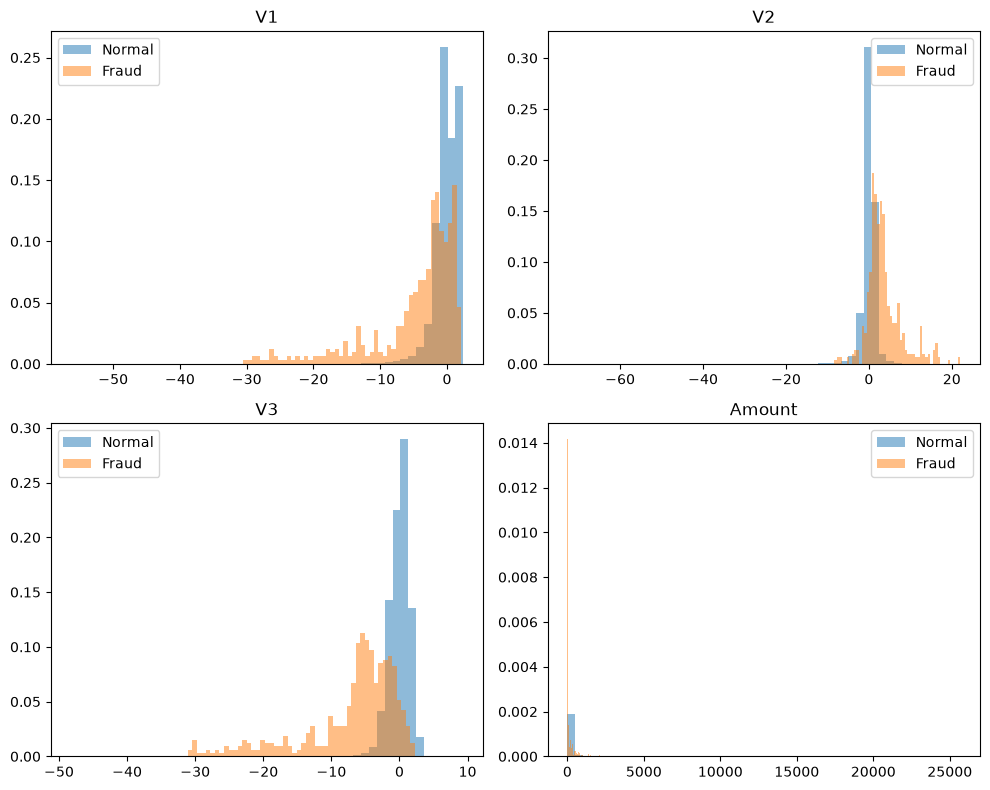

In [5]:
import matplotlib.pyplot as plt

features_to_check = ['V1', 'V2', 'V3', 'Amount']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feat in zip(axes.flatten(), features_to_check):
    ax.hist(df[df['Class']==0][feat], bins=50, alpha=0.5, label='Normal', density=True)
    ax.hist(df[df['Class']==1][feat], bins=50, alpha=0.5, label='Fraud', density=True)
    ax.set_title(feat)
    ax.legend()
plt.tight_layout()
plt.show()

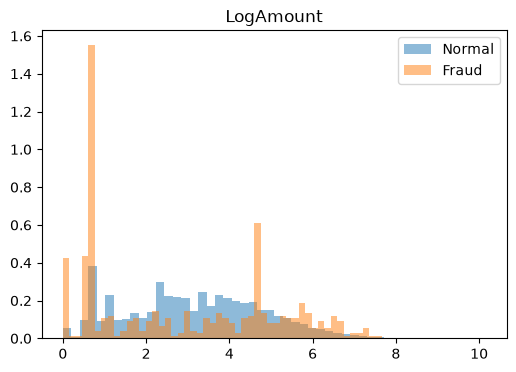

In [6]:
import numpy as np

df['LogAmount'] = np.log1p(df['Amount'])  # log(1 + Amount), handles Amount=0 safely

fig, ax = plt.subplots(figsize=(6,4))
ax.hist(df[df['Class']==0]['LogAmount'], bins=50, alpha=0.5, label='Normal', density=True)
ax.hist(df[df['Class']==1]['LogAmount'], bins=50, alpha=0.5, label='Fraud', density=True)
ax.set_title('LogAmount')
ax.legend()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

# Separate normal and fraud
normal = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

# Train: only normal transactions (used to fit the Gaussian)
train, normal_rest = train_test_split(normal, test_size=0.4, random_state=42)

# Split remaining normal + all fraud into val/test
val_normal, test_normal = train_test_split(normal_rest, test_size=0.5, random_state=42)
val_fraud, test_fraud = train_test_split(fraud, test_size=0.5, random_state=42)

val = pd.concat([val_normal, val_fraud])
test = pd.concat([test_normal, test_fraud])

print("Train:", train.shape, "(all normal)")
print("Val:", val.shape, f"({val['Class'].sum()} fraud)")
print("Test:", test.shape, f"({test['Class'].sum()} fraud)")

Train: (170589, 32) (all normal)
Val: (57109, 32) (246 fraud)
Test: (57109, 32) (246 fraud)


In [8]:
feature_cols = [f'V{i}' for i in range(1, 29)] + ['LogAmount']

def fit_gaussian(train_df, feature_cols):
    mu = train_df[feature_cols].mean()
    sigma2 = train_df[feature_cols].var()
    return mu, sigma2

mu, sigma2 = fit_gaussian(train, feature_cols)
print(mu.shape, sigma2.shape)

(29,) (29,)


In [9]:
def log_gaussian_prob(X, mu, sigma2):
    eps = 1e-10
    log_p = -0.5 * np.log(2 * np.pi * sigma2 + eps) - ((X - mu) ** 2) / (2 * sigma2 + eps)
    return log_p.sum(axis=1)  # sum of logs = log of the product across features

val['log_p'] = log_gaussian_prob(val[feature_cols], mu, sigma2)
val[['Class', 'log_p']].groupby('Class').describe()

log_p                                                               \
         count        mean         std          min         25%         50%   
Class                                                                         
0      56863.0  -38.002600   42.402918 -3550.416688  -37.494393  -33.022866   
1        246.0 -397.105462  464.372758 -3108.260046 -470.334277 -179.159072   

                             
             75%        max  
Class                        
0     -30.092032 -25.896620  
1     -95.197727 -30.551431

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.linspace(val['log_p'].min(), val['log_p'].max(), 1000)

best_f1 = 0
best_epsilon = None

for eps in thresholds:
    preds = (val['log_p'] < eps).astype(int)  # flag as fraud if log_p below threshold
    f1 = f1_score(val['Class'], preds)
    if f1 > best_f1:
        best_f1 = f1
        best_epsilon = eps

print("Best epsilon:", best_epsilon)
print("Best F1:", best_f1)

preds = (val['log_p'] < best_epsilon).astype(int)
print("Precision:", precision_score(val['Class'], preds))
print("Recall:", recall_score(val['Class'], preds))

Best epsilon: -219.93926663522825
Best F1: 0.37894736842105264
Precision: 0.3333333333333333
Recall: 0.43902439024390244


In [11]:
test['log_p'] = log_gaussian_prob(test[feature_cols], mu, sigma2)
test_preds = (test['log_p'] < best_epsilon).astype(int)

print("Test Precision:", precision_score(test['Class'], test_preds))
print("Test Recall:", recall_score(test['Class'], test_preds))
print("Test F1:", f1_score(test['Class'], test_preds))

Test Precision: 0.3384146341463415
Test Recall: 0.45121951219512196
Test F1: 0.3867595818815331


In [12]:
from sklearn.linear_model import LogisticRegression

# Build a proper supervised train set: use train (all normal) + val's fraud examples
# so the model actually sees some fraud during training
sup_train = pd.concat([train, val[val['Class']==1]])

clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
clf.fit(sup_train[feature_cols], sup_train['Class'])

test_preds_sup = clf.predict(test[feature_cols])

print("Supervised Precision:", precision_score(test['Class'], test_preds_sup))
print("Supervised Recall:", recall_score(test['Class'], test_preds_sup))
print("Supervised F1:", f1_score(test['Class'], test_preds_sup))

Supervised Precision: 0.14285714285714285
Supervised Recall: 0.9065040650406504
Supervised F1: 0.2468179302711677


In [13]:
from sklearn.metrics import f1_score

# Get probability scores instead of hard predictions
test_probs_sup = clf.predict_proba(test[feature_cols])[:, 1]

thresholds = np.linspace(0, 1, 1000)
best_f1_sup = 0
best_thresh_sup = None

for t in thresholds:
    preds = (test_probs_sup >= t).astype(int)
    f1 = f1_score(test['Class'], preds)
    if f1 > best_f1_sup:
        best_f1_sup = f1
        best_thresh_sup = t

print("Best threshold:", best_thresh_sup)
print("Best F1:", best_f1_sup)

final_preds_sup = (test_probs_sup >= best_thresh_sup).astype(int)
print("Precision:", precision_score(test['Class'], final_preds_sup))
print("Recall:", recall_score(test['Class'], final_preds_sup))

Best threshold: 0.998998998998999
Best F1: 0.8427672955974843
Precision: 0.8701298701298701
Recall: 0.8170731707317073
